#### Setup

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from src.paths import load_ccep, runs, electrodes_tsv

cc = load_ccep()
print(len(cc), "patients")

74 patients


###  All electrodes of all patients in one table

In [2]:
E = pd.concat(
    [electrodes_tsv(p["id"], p["ses"]).assign(patient=p["id"]) for p in cc],
    ignore_index=True,
)
print(E.shape)
for col in ["soz", "resected", "edge", "group"]:
    print(col, E[col].value_counts(dropna=False).to_dict())

(8655, 16)
soz {'no': 8302, 'yes': 353}
resected {'no': 7999, 'yes': 656}
edge {'no': 8482, 'yes': 173}
group {'grid': 4410, 'other': 3123, 'strip': 920, 'depth': 202}


#### Per patient: how many SOZ, resected and edge electrodes

In [3]:
yes = lambda s: (s == "yes").sum()

per = E.groupby("patient").agg(
    n_electrodes=("name", "size"),
    n_soz=("soz", yes),
    n_resected=("resected", yes),
    n_edge=("edge", yes),
)
per["soz_annotated"] = per["n_soz"] > 0
per["has_resection"] = per["n_resected"] > 0
per

,n_electrodes,n_soz,n_resected,n_edge,soz_annotated,has_resection
patient,,,,,,
sub-ccepAgeUMCU01,133,0,0,0,False,False
sub-ccepAgeUMCU02,96,0,0,0,False,False
sub-ccepAgeUMCU03,133,0,0,0,False,False
sub-ccepAgeUMCU04,128,0,0,0,False,False
sub-ccepAgeUMCU05,133,0,0,0,False,False
...,...,...,...,...,...,...
sub-ccepAgeUMCU70,68,0,0,0,False,False
sub-ccepAgeUMCU71,68,0,0,0,False,False
sub-ccepAgeUMCU72,133,0,0,0,False,False


Patients: SOZ marked? Resection marked?

In [4]:
pd.crosstab(per["soz_annotated"], per["has_resection"], margins=True)

has_resection,False,True,All
soz_annotated,,,
False,33,5,38
True,1,35,36
All,34,40,74


Electrodes: SOZ vs. resected

In [5]:
pd.crosstab(E["soz"], E["resected"], margins=True)

resected,no,yes,All
soz,,,
no,7887,415,8302
yes,112,241,353
All,7999,656,8655


SOZ electrodes that were NOT removed (left in the brain)

In [6]:
E["soz_not_resected"] = (E["soz"] == "yes") & (E["resected"] == "no")
per["n_soz_not_resected"] = E.groupby("patient")["soz_not_resected"].sum()

per[per["n_soz_not_resected"] > 0].sort_values("n_soz_not_resected", ascending=False)

,n_electrodes,n_soz,n_resected,n_edge,soz_annotated,has_resection,n_soz_not_resected
patient,,,,,,,
sub-ccepAgeUMCU58,133,37,23,4,True,True,22
sub-ccepAgeUMCU65,133,18,8,6,True,True,13
sub-ccepAgeUMCU47,133,11,0,0,True,False,11
sub-ccepAgeUMCU61,133,19,20,16,True,True,9
sub-ccepAgeUMCU07,130,24,48,8,True,True,8
sub-ccepAgeUMCU48,93,9,2,10,True,True,7
sub-ccepAgeUMCU42,133,20,51,6,True,True,7
sub-ccepAgeUMCU36,133,7,13,8,True,True,6
sub-ccepAgeUMCU62,133,11,6,2,True,True,5


How many N1 responses and stimulated pairs touch flagged electrodes?

In [7]:
rows = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    for r in runs(p):
        rec = el.reindex(r["channel_names"])   # match by name, not by position
        n1 = r["n1_peak_sample"]
        for flag in ["soz", "resected"]:
            flagged = rec[flag].eq("yes").values
            rows.append(dict(
                patient=p["id"],
                run=r["runName"],
                flag=flag,
                rec_channels_flagged=flagged.sum(),
                n1_at_flagged=int(np.sum(~np.isnan(n1[flagged, :]))),
                n1_total=int(np.sum(~np.isnan(n1))),
                stim_pairs_flagged=sum(
                    el.reindex(pair.split("-"))[flag].eq("yes").any()
                    for pair in r["stimpair_names"]
                ),
                stim_pairs_total=len(r["stimpair_names"]),
            ))

R = pd.DataFrame(rows)
summary = R.groupby("flag")[["rec_channels_flagged", "n1_at_flagged", "n1_total",
                             "stim_pairs_flagged", "stim_pairs_total"]].sum()
summary["share_n1_lost_%"] = (100 * summary["n1_at_flagged"] / summary["n1_total"]).round(1)
summary

,rec_channels_flagged,n1_at_flagged,n1_total,stim_pairs_flagged,stim_pairs_total,share_n1_lost_%
flag,,,,,,
resected,1024,4134,40168,690,4907,10.3
soz,528,2404,40168,415,4907,6.0


In [8]:
rows = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"])
    n1s = [r["n1_peak_sample"] for r in runs(p)]
    rows.append(dict(
        patient=p["id"],
        age=p["age"],
        soz_annotated=(el["soz"] == "yes").any(),
        has_resection=(el["resected"] == "yes").any(),
        n_electrodes=len(el),
        n_depth=(el["group"] == "depth").sum(),
        n_stim_pairs=sum(a.shape[1] for a in n1s),
        n1_rate=np.mean(np.concatenate([(~np.isnan(a)).ravel() for a in n1s])),
    ))

P = pd.DataFrame(rows)
print(P.groupby("soz_annotated").size())
P.groupby("soz_annotated")[["age", "n_electrodes", "n_depth", "n_stim_pairs", "n1_rate"]].median().round(3)

soz_annotated
False    38
True     36
dtype: int64


,age,n_electrodes,n_depth,n_stim_pairs,n1_rate
soz_annotated,,,,,
False,16.5,133.0,0.0,63.0,0.073
True,17.5,133.0,0.0,55.5,0.067


Does removing the SOZ change the spread? (annotated patients only)

In [9]:
import warnings; warnings.filterwarnings("ignore")

rows = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    if not (el["soz"] == "yes").any():
        continue                                         # only patients with SOZ marked
    for r in runs(p):
        names = r["channel_names"]
        rec = el.reindex(names)                          # match by name
        n1 = r["n1_peak_sample"]
        good = np.isin(np.arange(1, len(names) + 1), np.atleast_1d(r["good_channels"]))  # 1-based indices
        good &= rec["group"].ne("depth").values
        soz = rec["soz"].eq("yes").values
        for j, pair in enumerate(r["stimpair_names"]):
            a, b = pair.split("-")
            base = good & ~np.isin(names, [a, b])        # drop the stimulated electrodes
            has = ~np.isnan(n1[:, j])
            rows.append(dict(
                patient=p["id"], pair=pair,
                spread_all=100 * has[base].mean(),
                spread_no_soz=100 * has[base & ~soz].mean(),
                stim_in_soz=el.reindex([a, b])["soz"].eq("yes").any(),
            ))

S = pd.DataFrame(rows).dropna()
S["change"] = S["spread_all"] - S["spread_no_soz"]
print(len(S), "pairs |", S["patient"].nunique(), "patients")
print("rank correlation:", round(S["spread_all"].corr(S["spread_no_soz"], method="spearman"), 3))
print("pairs changing by 2 points or less:", round(100 * (S["change"].abs() <= 2).mean()), "%")
S.head()

2174 pairs | 36 patients
rank correlation: 0.971
pairs changing by 2 points or less: 70 %


,patient,pair,spread_all,spread_no_soz,stim_in_soz,change
0,sub-ccepAgeUMCU07,TOc01-TOc02,3.669725,3.488372,True,0.181353
1,sub-ccepAgeUMCU07,TOc02-TOc03,6.422018,4.705882,False,1.716136
2,sub-ccepAgeUMCU07,TOc03-TOc04,8.256881,8.235294,False,0.021587
3,sub-ccepAgeUMCU07,TOc04-TOc05,7.339450,8.235294,False,-0.895845
4,sub-ccepAgeUMCU07,TOc05-TOc06,11.926606,10.588235,False,1.338370


Plot style

In [10]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})
C_OUT, C_IN = "#2a78b5", "#d0603a"   # blue = pulse outside SOZ, orange = pulse inside SOZ

with vs. without SOZ, one dot per pair

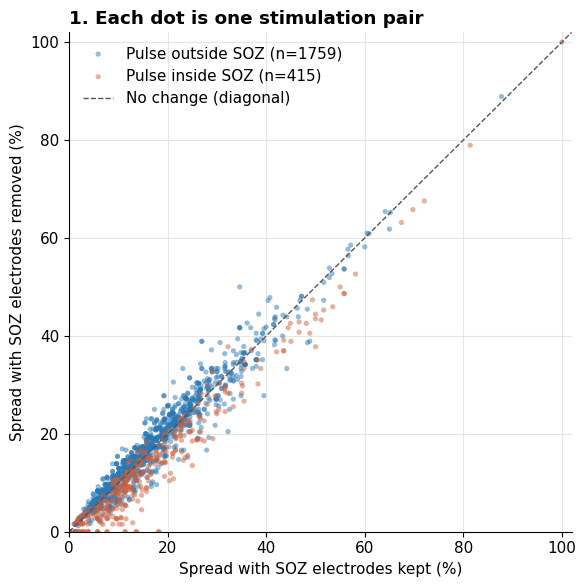

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
for flag, col, lab in [(False, C_OUT, "Pulse outside SOZ"), (True, C_IN, "Pulse inside SOZ")]:
    d = S[S["stim_in_soz"] == flag]
    ax.scatter(d["spread_all"], d["spread_no_soz"], s=14, alpha=0.5, color=col,
               edgecolor="none", label=f"{lab} (n={len(d)})")
m = max(S["spread_all"].max(), S["spread_no_soz"].max()) + 2
ax.plot([0, m], [0, m], color="#555", lw=1, ls="--", label="No change (diagonal)")
ax.set_xlim(0, m); ax.set_ylim(0, m)
ax.set_xlabel("Spread with SOZ electrodes kept (%)")
ax.set_ylabel("Spread with SOZ electrodes removed (%)")
ax.set_title("1. Each dot is one stimulation pair", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

size of the change, and pulses inside vs. outside the SOZ

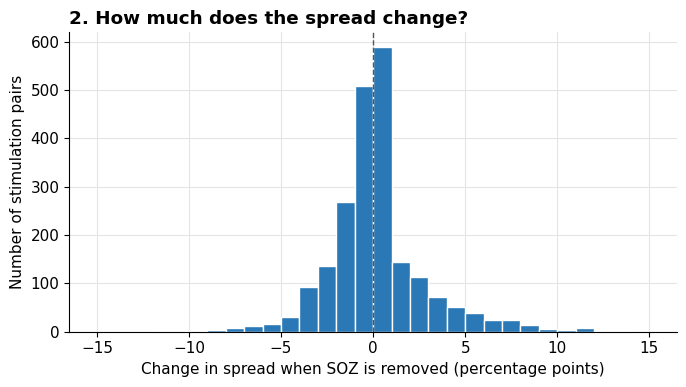

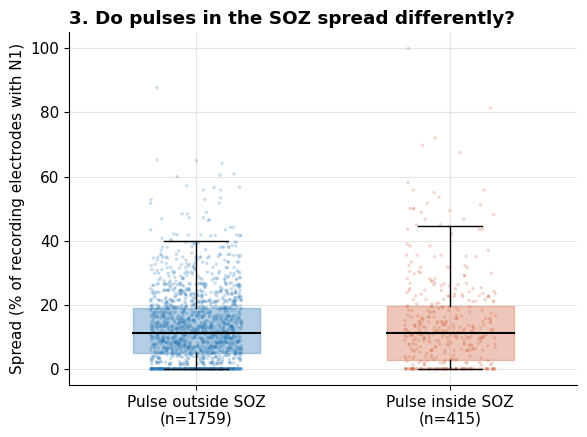

In [12]:
# Plot 2
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(S["change"], bins=np.arange(-15, 15.5, 1), color=C_OUT, edgecolor="white")
ax.axvline(0, color="#555", lw=1, ls="--")
ax.set_xlabel("Change in spread when SOZ is removed (percentage points)")
ax.set_ylabel("Number of stimulation pairs")
ax.set_title("2. How much does the spread change?", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

# Plot 3
fig, ax = plt.subplots(figsize=(6, 4.5))
data = [S.loc[~S["stim_in_soz"], "spread_all"], S.loc[S["stim_in_soz"], "spread_all"]]
bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color="black", lw=1.5))
for patch, col in zip(bp["boxes"], [C_OUT, C_IN]):
    patch.set_facecolor(col); patch.set_alpha(0.35); patch.set_edgecolor(col)
rng = np.random.default_rng(0)
for i, (d, col) in enumerate(zip(data, [C_OUT, C_IN]), start=1):
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(d)), d, s=6, alpha=0.25, color=col, edgecolor="none")
ax.set_xticks([1, 2], [f"Pulse outside SOZ\n(n={len(data[0])})", f"Pulse inside SOZ\n(n={len(data[1])})"])
ax.set_ylabel("Spread (% of recording electrodes with N1)")
ax.set_title("3. Do pulses in the SOZ spread differently?", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

change per patient

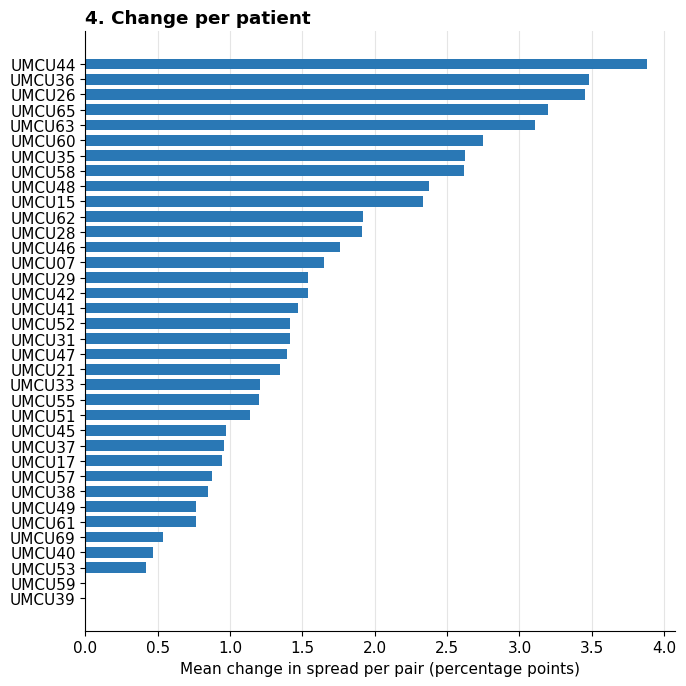

In [13]:
P = S.groupby("patient")["change"].apply(lambda x: x.abs().mean()).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh([p.replace("sub-ccepAge", "") for p in P.index], P.values, color=C_OUT, height=0.7)
ax.set_xlabel("Mean change in spread per pair (percentage points)")
ax.set_title("4. Change per patient", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

SOZ patients left after each exclusion rule

In [14]:
from src.paths import channels_tsv

out = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    if not el["soz"].eq("yes").any():
        continue
    D = p["nativeElecDistances"]                       # same order as channel_names
    st = dict(patient=p["id"], any_soz=True, surface=False, labelled=False,
              good=False, not_resected=False, far_13mm=False)
    for r in runs(p):
        names = list(r["channel_names"])
        rec = el.reindex(names)
        ch = channels_tsv(p["id"], p["ses"], r["runName"]).set_index("name")
        good = ch.reindex(names)["status"].eq("good").values
        soz = rec["soz"].eq("yes").values
        surf = rec["group"].isin(["grid", "strip"]).values
        lab = (pd.to_numeric(rec["Destrieux_label"], errors="coerce") > 0).values & rec["hemisphere"].isin(["L", "R"]).values
        res = rec["resected"].eq("yes").values
        m1 = soz & surf; m2 = m1 & lab; m3 = m2 & good; m4 = m3 & ~res
        st["surface"] |= m1.any(); st["labelled"] |= m2.any()
        st["good"] |= m3.any(); st["not_resected"] |= m4.any()
        for pair in r["stimpair_names"]:
            si = [names.index(x) for x in pair.split("-") if x in names]
            far = (D[:, si].min(axis=1) >= 13) & ~np.isin(np.arange(len(names)), si)
            if (m4 & far).any():
                st["far_13mm"] = True
                break
    out.append(st)

T = pd.DataFrame(out).set_index("patient")
print(T.sum())                       # patients still having SOZ after each step
T[~T["far_13mm"]]                    # patients whose SOZ is fully removed by the other rules

any_soz         36
surface         34
labelled        34
good            34
not_resected    21
far_13mm        21
dtype: int64


,any_soz,surface,labelled,good,not_resected,far_13mm
patient,,,,,,
sub-ccepAgeUMCU17,True,True,True,True,False,False
sub-ccepAgeUMCU21,True,True,True,True,False,False
sub-ccepAgeUMCU26,True,True,True,True,False,False
sub-ccepAgeUMCU31,True,True,True,True,False,False
sub-ccepAgeUMCU33,True,True,True,True,False,False
sub-ccepAgeUMCU38,True,True,True,True,False,False
sub-ccepAgeUMCU39,True,False,False,False,False,False
sub-ccepAgeUMCU41,True,True,True,True,False,False
sub-ccepAgeUMCU49,True,True,True,True,False,False


ROC curve with the area under it -  basically answers if modelling helps us with rest of Soz

2092 electrodes | 36 patients | AUC = 0.61


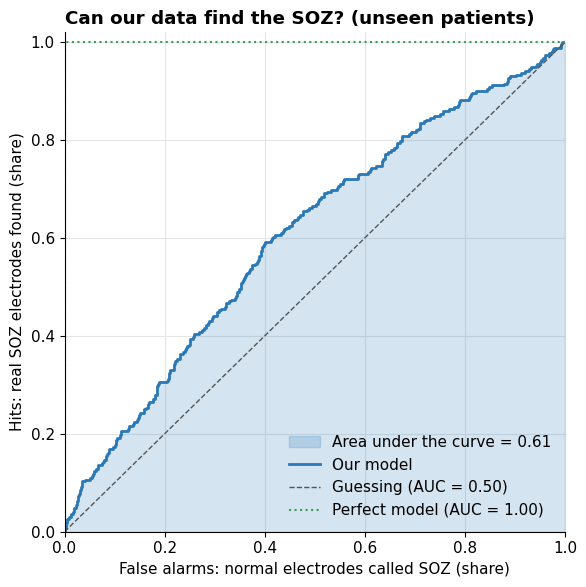

In [15]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

# 1) three numbers per electrode
feats = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    acc = {}
    new = lambda: dict(rec_n=0, rec_hits=0, lat=[], stim_n=0, stim_hits=0)
    for r in runs(p):
        n1, tt = r["n1_peak_sample"], r["tt"]
        has = ~np.isnan(n1)
        for i, ch in enumerate(r["channel_names"]):          # as recording electrode
            a = acc.setdefault(ch, new())
            a["rec_n"] += n1.shape[1]
            a["rec_hits"] += has[i].sum()
            a["lat"] += list(tt[n1[i][has[i]].astype(int) - 1] * 1000)
        for j, pair in enumerate(r["stimpair_names"]):       # as stimulated electrode
            for e in pair.split("-"):
                a = acc.setdefault(e, new())
                a["stim_n"] += 1
                a["stim_hits"] += has[:, j].sum()
    for ch, a in acc.items():
        if ch not in el.index:
            continue
        feats.append(dict(
            patient=p["id"], soz=el.loc[ch, "soz"] == "yes", group=el.loc[ch, "group"],
            in_rate=a["rec_hits"] / a["rec_n"] if a["rec_n"] else np.nan,
            mean_lat=np.mean(a["lat"]) if a["lat"] else np.nan,
            out_resp=a["stim_hits"] / a["stim_n"] if a["stim_n"] else np.nan,
        ))
F = pd.DataFrame(feats)

# 2) only annotated patients, surface electrodes
annotated = F.groupby("patient")["soz"].transform("any")
D = F[annotated & (F["group"] != "depth")].dropna(subset=["in_rate", "mean_lat", "out_resp"])
X = D[["in_rate", "mean_lat", "out_resp"]].values
y = D["soz"].values

# 3) model, always tested on unseen patients
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
prob = cross_val_predict(model, X, y, groups=D["patient"], cv=GroupKFold(5),
                         method="predict_proba")[:, 1]
auc = roc_auc_score(y, prob)
print(len(D), "electrodes |", D["patient"].nunique(), "patients | AUC =", round(auc, 2))

# 4) ROC curve
fpr, tpr, _ = roc_curve(y, prob)
fig, ax = plt.subplots(figsize=(6, 6))
ax.fill_between(fpr, tpr, color="#2a78b5", alpha=0.2, label=f"Area under the curve = {auc:.2f}")
ax.plot(fpr, tpr, color="#2a78b5", lw=2, label="Our model")
ax.plot([0, 1], [0, 1], color="#555", ls="--", lw=1, label="Guessing (AUC = 0.50)")
ax.plot([0, 0, 1], [0, 1, 1], color="#3a9d5d", ls=":", lw=1.5, label="Perfect model (AUC = 1.00)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("False alarms: normal electrodes called SOZ (share)")
ax.set_ylabel("Hits: real SOZ electrodes found (share)")
ax.set_title("Can our data find the SOZ? (unseen patients)", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

# Task 4 

In [16]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from src.paths import load_ccep, runs

cc = load_ccep()
print(len(cc), "patients")

74 patients


In [17]:
rows = []
for p in cc:
    for r in runs(p):
        cur = r["stimpair_currents"]
        if cur.dtype != object:            # normal case: one number per pair
            cur = list(cur)
        for j, pair in enumerate(r["stimpair_names"]):
            mA = np.round(np.ravel(cur[j]) * 1000, 1)       # stored in ampere -> mA
            rows.append(dict(
                patient=p["id"],
                run=r["runName"],
                pair=pair,
                current_mA=mA[0] if mA.size == 1 else np.nan,
                current_label=(f"{mA[0]:g} mA" if mA.size == 1
                               else "mixed (" + " + ".join(f"{v:g}" for v in mA) + " mA)"),
                region_1=r["stimpair_DestrieuxLabel"][j][0],
                region_2=r["stimpair_DestrieuxLabel"][j][1],
            ))

C = pd.DataFrame(rows)
C["current_group"] = np.where(C["current_label"].str.startswith("mixed"), "mixed", C["current_label"])
print(len(C), "stimulation pairs")
C.head()

4907 stimulation pairs


,patient,run,pair,current_mA,current_label,region_1,region_2,current_group
0,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT01-PT02,7.0,7 mA,G_occipital_middle,G_occipital_middle,7 mA
1,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT03-PT02,7.0,7 mA,G_temporal_inf,G_occipital_middle,7 mA
2,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT03-PT04,7.0,7 mA,G_temporal_inf,G_temporal_inf,7 mA
3,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT05-PT04,7.0,7 mA,G_temporal_middle,G_temporal_inf,7 mA
4,sub-ccepAgeUMCU01,sub-ccepAgeUMCU01_ses-1_task-SPESclin_run-0214...,PT05-PT06,7.0,7 mA,G_temporal_middle,G_temporal_middle,7 mA


In [18]:
order = ["8 mA", "4 mA", "7 mA", "6 mA", "2 mA", "mixed"]

tab = C["current_group"].value_counts().reindex(order).rename("stimulation_pairs").to_frame()
tab["share_%"] = (100 * tab["stimulation_pairs"] / len(C)).round(1)
tab["patients"] = C.groupby("current_group")["patient"].nunique().reindex(order)
tab

,stimulation_pairs,share_%,patients
current_group,,,
8 mA,4336,88.4,73
4 mA,296,6.0,18
7 mA,218,4.4,1
6 mA,43,0.9,4
2 mA,6,0.1,1
mixed,8,0.2,6


In [19]:
C.loc[C["current_group"] == "mixed", "current_label"].value_counts()

current_label
mixed (4 + 8 mA)    5
mixed (6 + 7 mA)    2
mixed (6 + 8 mA)    1
Name: count, dtype: int64

#### after exclusion

In [20]:
import warnings; warnings.filterwarnings("ignore")
from src.paths import electrodes_tsv, channels_tsv

flags = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    for r in runs(p):
        ch = channels_tsv(p["id"], p["ses"], r["runName"]).set_index("name")
        for pair in r["stimpair_names"]:
            e = el.reindex(pair.split("-"))                  # the 2 stimulated electrodes
            status = ch.reindex(pair.split("-"))["status"]
            has_label = (pd.to_numeric(e["Destrieux_label"], errors="coerce") > 0) & e["hemisphere"].isin(["L", "R"])
            flags.append(dict(
                depth=(~e["group"].isin(["grid", "strip"])).any(),
                no_label=(~has_label).any(),
                bad_channel=status.ne("good").any(),
                resected=e["resected"].eq("yes").any(),
                soz=e["soz"].eq("yes").any(),
            ))

rules = ["depth", "no_label", "bad_channel", "resected", "soz"]
C = pd.concat([C.reset_index(drop=True), pd.DataFrame(flags)], axis=1)
C["kept"] = ~C[rules].any(axis=1)
C["first_reason"] = C[rules].idxmax(axis=1).where(~C["kept"], "kept")   # first rule that removes the pair

order = ["8 mA", "4 mA", "7 mA", "6 mA", "2 mA", "mixed"]
T = pd.crosstab(C["current_group"], C["first_reason"]).reindex(order).fillna(0).astype(int)
T = T.reindex(columns=["kept"] + rules, fill_value=0)
T["total"] = T.sum(axis=1)
T["kept_%"] = (100 * T["kept"] / T["total"]).round(1)
T

first_reason,kept,depth,no_label,bad_channel,resected,soz,total,kept_%
current_group,,,,,,,,
8 mA,3386,45,12,235,546,112,4336,78.1
4 mA,234,47,0,2,9,4,296,79.1
7 mA,204,12,2,0,0,0,218,93.6
6 mA,43,0,0,0,0,0,43,100.0
2 mA,0,6,0,0,0,0,6,0.0
mixed,5,3,0,0,0,0,8,62.5


In [21]:
K = C[C["kept"]]

after = K["current_group"].value_counts().reindex(order).fillna(0).astype(int).rename("pairs_after").to_frame()
after["share_%"] = (100 * after["pairs_after"] / len(K)).round(1)
after["patients"] = K.groupby("current_group")["patient"].nunique().reindex(order).fillna(0).astype(int)
after["pairs_before"] = C["current_group"].value_counts().reindex(order)
print(len(K), "of", len(C), "pairs kept")
after

3872 of 4907 pairs kept


,pairs_after,share_%,patients,pairs_before
current_group,,,,
8 mA,3386,87.4,73,4336
4 mA,234,6.0,12,296
7 mA,204,5.3,1,218
6 mA,43,1.1,4,43
2 mA,0,0.0,0,6
mixed,5,0.1,4,8


#### Spread of every kept pair (all rules applied)

In [22]:
import warnings; warnings.filterwarnings("ignore")
from src.paths import electrodes_tsv, channels_tsv

SM_NR = {3, 4, 28, 29, 45, 67, 68, 69}   # sensorimotor cortex as Destrieux numbers

rows = []
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"]).set_index("name")
    D = p["nativeElecDistances"]                          # order = electrodes.tsv
    pos = {name: i for i, name in enumerate(el.index)}
    for r in runs(p):
        names = list(r["channel_names"])
        rec = el.reindex(names)
        ch = channels_tsv(p["id"], p["ses"], r["runName"]).set_index("name")
        good = ch.reindex(names)["status"].eq("good").values
        label = (pd.to_numeric(rec["Destrieux_label"], errors="coerce") > 0).values & rec["hemisphere"].isin(["L", "R"]).values
        surface = rec["group"].isin(["grid", "strip"]).values
        ok = good & label & surface & rec["resected"].ne("yes").values & rec["soz"].ne("yes").values
        row_idx = np.array([pos.get(n, -1) for n in names])
        n1 = r["n1_peak_sample"]
        cur = r["stimpair_currents"]
        if cur.dtype != object:
            cur = list(cur)
        for j, pair in enumerate(r["stimpair_names"]):
            mA = np.round(np.ravel(cur[j]) * 1000, 1)
            if mA.size != 1:
                continue                                      # skip "mixed" pairs
            a, b = pair.split("-")
            si = [names.index(x) for x in (a, b) if x in names]
            if len(si) < 2 or not ok[si].all():
                continue                                      # exclusion rules on stimulated electrodes
            d = np.where(row_idx >= 0, D[np.clip(row_idx, 0, None)][:, [pos[a], pos[b]]].min(axis=1), np.nan)
            far = d >= 13
            far[si] = False
            base = ok & far                                   # usable recording electrodes
            if base.sum() == 0:
                continue
            nrs = [int(x) for x in np.ravel(r["stimpair_DestrieuxNr"][j])]
            rows.append(dict(
                patient=p["id"], age=p["age"], pair=pair, mA=mA[0], n_rec=int(base.sum()),
                spread=100 * np.mean(~np.isnan(n1[base, j])),
                pair_spacing_mm=D[pos[a], pos[b]],
                region=f'{el.loc[a, "hemisphere"]}{nrs[0]}',
                region_name=str(r["stimpair_DestrieuxLabel"][j][0]),
                sensorimotor=any(n in SM_NR for n in nrs),
            ))

S = pd.DataFrame(rows)
print(len(S), "pairs |", S["patient"].nunique(), "patients")
pd.crosstab(S["mA"], S["sensorimotor"], margins=True)

3867 pairs | 74 patients


sensorimotor,False,True,All
mA,,,
4.0,89,145,234
6.0,20,23,43
7.0,182,22,204
8.0,2644,742,3386
All,2935,932,3867


Which patients got which currents?

In [23]:
P = S.groupby("patient").agg(
    age=("age", "first"),
    pairs=("mA", "size"),
    currents=("mA", lambda x: " / ".join(f"{v:g}" for v in sorted(set(x)))),
    share_8mA=("mA", lambda x: round((x == 8).mean(), 2)),
)
print(P["currents"].value_counts())
P[P["currents"] != "8"]

currents
8        58
4 / 8    12
6 / 8     3
6 / 7     1
Name: count, dtype: int64


,age,pairs,currents,share_8mA
patient,,,,
sub-ccepAgeUMCU01,15,206,6 / 7,0.00
sub-ccepAgeUMCU02,35,79,6 / 8,0.86
sub-ccepAgeUMCU09,21,88,6 / 8,0.98
sub-ccepAgeUMCU12,14,95,6 / 8,0.71
sub-ccepAgeUMCU33,18,45,4 / 8,0.82
sub-ccepAgeUMCU34,7,42,4 / 8,0.45
sub-ccepAgeUMCU37,28,37,4 / 8,0.86
sub-ccepAgeUMCU38,21,40,4 / 8,0.70
sub-ccepAgeUMCU59,50,32,4 / 8,0.75


Where are 4, 6 and 7 mA? And is the electrode spacing different?

In [24]:
for m in [4.0, 6.0, 7.0]:
    g = S[S["mA"] == m]
    print(f"\n--- {m:g} mA: {len(g)} pairs ---")
    print("patients:", g["patient"].value_counts().to_dict())
    print("in sensorimotor:", g["sensorimotor"].sum(), "| elsewhere:", (~g["sensorimotor"]).sum())
    print("top regions:", g["region_name"].value_counts().head(5).to_dict())

print("\nMedian spacing of the stimulated pair and number of recording electrodes:")
S.groupby("mA")[["pair_spacing_mm", "n_rec"]].median().round(1)


--- 4 mA: 234 pairs ---
patients: {'sub-ccepAgeUMCU67': 65, 'sub-ccepAgeUMCU73': 46, 'sub-ccepAgeUMCU66': 30, 'sub-ccepAgeUMCU34': 23, 'sub-ccepAgeUMCU74': 15, 'sub-ccepAgeUMCU38': 12, 'sub-ccepAgeUMCU70': 11, 'sub-ccepAgeUMCU62': 9, 'sub-ccepAgeUMCU33': 8, 'sub-ccepAgeUMCU59': 8, 'sub-ccepAgeUMCU37': 5, 'sub-ccepAgeUMCU63': 2}
in sensorimotor: 145 | elsewhere: 89
top regions: {'G_postcentral': 48, 'G_precentral': 43, 'G_pariet_inf-Supramar': 15, 'G_front_sup': 14, 'G_temp_sup-Lateral': 14}

--- 6 mA: 43 pairs ---
patients: {'sub-ccepAgeUMCU12': 28, 'sub-ccepAgeUMCU02': 11, 'sub-ccepAgeUMCU01': 2, 'sub-ccepAgeUMCU09': 2}
in sensorimotor: 23 | elsewhere: 20
top regions: {'G_precentral': 10, 'G_front_sup': 9, 'G_postcentral': 6, 'G_and_S_subcentral': 4, 'G_front_inf-Triangul': 3}

--- 7 mA: 204 pairs ---
patients: {'sub-ccepAgeUMCU01': 204}
in sensorimotor: 22 | elsewhere: 182
top regions: {'G_temporal_middle': 36, 'G_pariet_inf-Angular': 27, 'G_pariet_inf-Supramar': 18, 'G_temporal_inf

,pair_spacing_mm,n_rec
mA,,
4.0,10.3,52.0
6.0,10.4,100.0
7.0,10.6,93.0
8.0,10.3,54.0


Dose check: median spread per current and area

In [25]:
S.groupby(["sensorimotor", "mA"])["spread"].median().unstack().round(1)

mA,4.0,6.0,7.0,8.0
sensorimotor,,,,
False,2.4,3.1,4.4,6.7
True,4.5,3.0,4.3,8.8


Same patient + same region test, and plots

48 patient-region cases
weaker spreads less: 30 | more: 15
median difference (points): 1.7
Wilcoxon p = 0.015


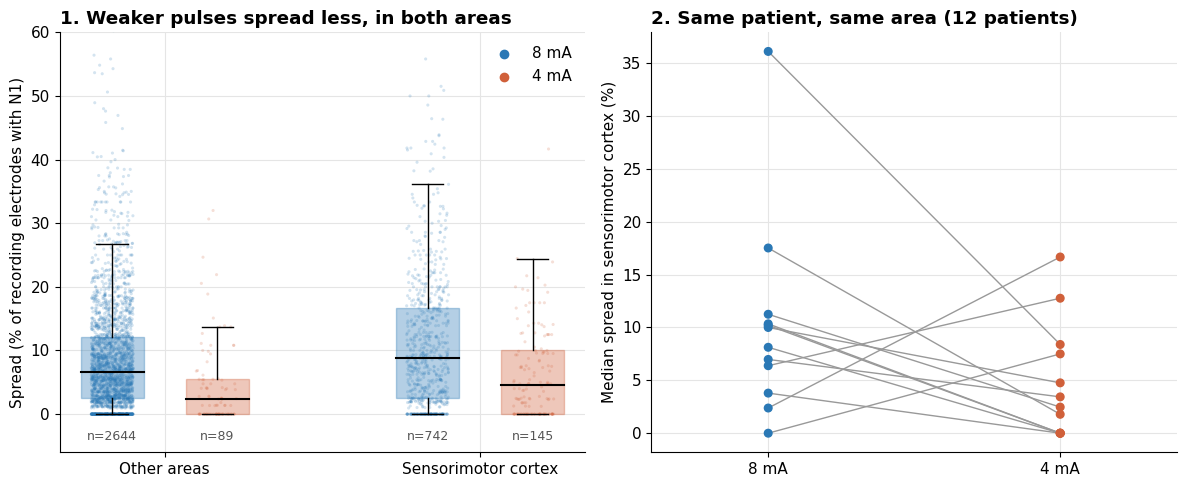

In [26]:
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt

M = S.groupby(["patient", "region"]).filter(lambda g: (g["mA"] == 8).any() and (g["mA"] < 8).any())
G = M.assign(weaker=M["mA"] < 8).groupby(["patient", "region", "weaker"])["spread"].median().unstack()
print(len(G), "patient-region cases")
print("weaker spreads less:", (G[True] < G[False]).sum(), "| more:", (G[True] > G[False]).sum())
print("median difference (points):", round((G[False] - G[True]).median(), 1))
print("Wilcoxon p =", round(wilcoxon(G[False], G[True]).pvalue, 3))

sm = S[S["sensorimotor"] & S["mA"].isin([4, 8])]
both = sm.groupby("patient")["mA"].agg(lambda x: {4.0, 8.0} <= set(x))
W = sm[sm["patient"].isin(both[both].index)].groupby(["patient", "mA"])["spread"].median().unstack()

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})
C8, C4 = "#2a78b5", "#d0603a"
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
groups = {("Other areas", 8): 1, ("Other areas", 4): 2, ("Sensorimotor", 8): 4, ("Sensorimotor", 4): 5}
for (area, mA), x in groups.items():
    d = S[(S["sensorimotor"] == (area == "Sensorimotor")) & (S["mA"] == mA)]["spread"]
    col = C8 if mA == 8 else C4
    b = ax.boxplot([d], positions=[x], widths=0.6, patch_artist=True, showfliers=False,
                   medianprops=dict(color="black", lw=1.5))
    b["boxes"][0].set_facecolor(col); b["boxes"][0].set_alpha(0.35); b["boxes"][0].set_edgecolor(col)
    ax.scatter(x + rng.uniform(-0.2, 0.2, len(d)), d, s=5, alpha=0.2, color=col, edgecolor="none")
    ax.text(x, -4, f"n={len(d)}", ha="center", fontsize=9, color="#555")
ax.set_xticks([1.5, 4.5], ["Other areas", "Sensorimotor cortex"]); ax.set_ylim(-6, 60)
ax.set_ylabel("Spread (% of recording electrodes with N1)")
ax.scatter([], [], color=C8, label="8 mA"); ax.scatter([], [], color=C4, label="4 mA")
ax.legend(frameon=False)
ax.set_title("1. Weaker pulses spread less, in both areas", loc="left", fontweight="bold")

ax = axes[1]
for pid, row in W.iterrows():
    ax.plot([0, 1], [row[8.0], row[4.0]], color="#999", lw=1)
    ax.scatter([0, 1], [row[8.0], row[4.0]], color=[C8, C4], s=30, zorder=3)
ax.set_xticks([0, 1], ["8 mA", "4 mA"]); ax.set_xlim(-0.4, 1.4)
ax.set_ylabel("Median spread in sensorimotor cortex (%)")
ax.set_title(f"2. Same patient, same area ({len(W)} patients)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

Mixed model: effect of each current vs. 8 mA

In [27]:
import statsmodels.formula.api as smf

model = smf.mixedlm("spread ~ C(mA, Treatment(8.0)) + sensorimotor + np.log(n_rec)",
                    S, groups=S["patient"]).fit()
model.summary().tables[1]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,37.341,6.400,5.835,0.000,24.797,49.884
"C(mA, Treatment(8.0))[T.4.0]",-4.233,0.803,-5.273,0.000,-5.806,-2.660
"C(mA, Treatment(8.0))[T.6.0]",-2.586,1.480,-1.748,0.080,-5.486,0.314
"C(mA, Treatment(8.0))[T.7.0]",0.321,3.671,0.088,0.930,-6.874,7.517
sensorimotor[T.True],1.725,0.356,4.841,0.000,1.027,2.424
np.log(n_rec),-7.210,1.634,-4.412,0.000,-10.413,-4.007
Group Var,18.531,0.454,,,,


##### What do we lose with 8 mA only?

In [28]:
E8 = S[S["mA"] == 8]
summary = pd.DataFrame({
    "all currents": [len(S), S["patient"].nunique(), S["region"].nunique(), S["sensorimotor"].sum()],
    "only 8 mA":    [len(E8), E8["patient"].nunique(), E8["region"].nunique(), E8["sensorimotor"].sum()],
}, index=["pairs", "patients", "stimulated regions", "sensorimotor pairs"])
print("regions lost:", set(S["region"]) - set(E8["region"]))
summary

regions lost: {'R40', 'L45'}


,all currents,only 8 mA
pairs,3867,3386
patients,74,73
stimulated regions,109,107
sensorimotor pairs,932,742


Are weak-pulse patients special? And the neighbour check (< 1 cm, same patient)

In [29]:
S["got_weak_pulses"] = S["patient"].isin(S.loc[S["mA"] < 8, "patient"].unique())
print(S[S["mA"] == 8].groupby("got_weak_pulses")["spread"].agg(["median", "size"]).round(1))

res = []
for pid, g in S.groupby("patient"):
    if not (g["mA"] < 8).any() or not (g["mA"] == 8).any():
        continue
    p = next(q for q in cc if q["id"] == pid)
    el = electrodes_tsv(p["id"], p["ses"])
    pos = {n: i for i, n in enumerate(el["name"])}
    D = p["nativeElecDistances"]
    strong = g[g["mA"] == 8]
    strong_sets = strong["pair"].apply(lambda x: tuple(sorted(x.split("-"))))
    for _, weak in g[g["mA"] < 8].iterrows():
        w_idx = [pos[x] for x in weak["pair"].split("-")]
        dist = strong["pair"].apply(lambda pr: D[np.ix_(w_idx, [pos[x] for x in pr.split("-")])].min())
        near = strong[(dist <= 10) & (strong_sets != tuple(sorted(weak["pair"].split("-"))))]
        if len(near):
            res.append(dict(patient=pid, mA=weak["mA"], weak=weak["spread"], strong_near=near["spread"].median()))

R = pd.DataFrame(res)
print(len(R), "weak pulses with an 8 mA neighbour |", R["patient"].nunique(), "patients")
print("weak lower:", (R["weak"] < R["strong_near"]).sum(), "| higher:", (R["weak"] > R["strong_near"]).sum())
print("median difference (points):", round((R["strong_near"] - R["weak"]).median(), 2))
print("Wilcoxon p =", wilcoxon(R["strong_near"], R["weak"]).pvalue)
Rp = R.groupby("patient")[["strong_near", "weak"]].median()
print("weaker lower in", (Rp["weak"] < Rp["strong_near"]).sum(), "of", len(Rp), "patients")

                 median  size
got_weak_pulses              
False               7.4  2791
True                4.7   595
137 weak pulses with an 8 mA neighbour | 15 patients
weak lower: 90 | higher: 34
median difference (points): 2.04
Wilcoxon p = 4.5330925607009416e-08
weaker lower in 12 of 15 patients


How far are the "elsewhere" 4 mA pulses from the sensorimotor cortex?

In [30]:
out = []
for _, row in S[(S["mA"] == 4) & ~S["sensorimotor"]].iterrows():
    p = next(q for q in cc if q["id"] == row["patient"])
    el = electrodes_tsv(p["id"], p["ses"])
    D = p["nativeElecDistances"]
    pos = {n: i for i, n in enumerate(el["name"])}
    nr = pd.to_numeric(el["Destrieux_label"], errors="coerce")
    sm_idx = np.where(nr.isin(list(SM_NR)) & el["group"].isin(["grid", "strip"]))[0]
    pair_idx = [pos[x] for x in row["pair"].split("-")]
    out.append(dict(patient=row["patient"], region=row["region_name"],
                    dist_to_sm_mm=D[np.ix_(pair_idx, sm_idx)].min() if len(sm_idx) else np.nan))

O = pd.DataFrame(out)
print(len(O), "pulses at 4 mA outside the sensorimotor cortex")
print("< 13 mm:", (O["dist_to_sm_mm"] < 13).sum(),
      "| 13–20 mm:", O["dist_to_sm_mm"].between(13, 20).sum(),
      "| > 20 mm:", (O["dist_to_sm_mm"] > 20).sum())

far = O[O["dist_to_sm_mm"] > 20]
weak_patients = S.loc[S["mA"] == 4, "patient"].unique()
rows = []
for region, g in far.groupby("region"):
    same = S[S["patient"].isin(weak_patients) & (S["region_name"] == region)]
    rows.append(dict(region=region, pulses_4mA=len(g), patients_4mA=g["patient"].nunique(),
                     pulses_8mA_same_patients=int((same["mA"] == 8).sum())))
pd.DataFrame(rows).sort_values("pulses_4mA", ascending=False)

89 pulses at 4 mA outside the sensorimotor cortex
< 13 mm: 35 | 13–20 mm: 14 | > 20 mm: 40


,region,pulses_4mA,patients_4mA,pulses_8mA_same_patients
8,G_temporal_middle,10,2,7
2,G_front_sup,5,2,35
3,G_oc-temp_med-Parahip,5,1,0
10,Pole_temporal,5,1,3
4,G_pariet_inf-Angular,4,2,33
7,G_temp_sup-Lateral,4,1,18
0,G&S_cingul-Mid-Ant,2,1,1
1,G_front_inf-Triangul,2,1,19
5,G_pariet_inf-Supramar,1,1,35
6,G_parietal_sup,1,1,33


107 regions
rank correlation: 0.987
          mean  median    max  size
has_weak                           
False     0.00    0.00   0.00    62
True      0.99    0.58  13.94    45


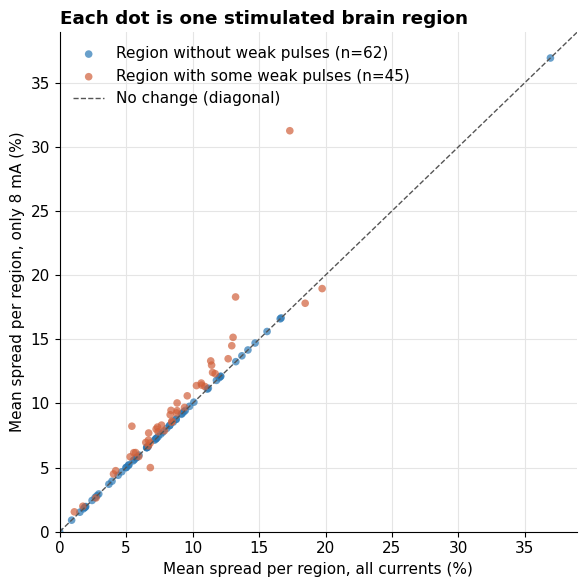

,spread_all,sensorimotor,spread_8mA,change,has_weak
region,,,,,
R68,17.3,True,31.2,13.9,True
R23,13.2,False,18.3,5.1,True
L3,5.4,True,8.2,2.8,True
R12,13.0,True,15.1,2.1,True
R28,11.4,True,13.3,1.9,True


In [31]:
import matplotlib.pyplot as plt

per_region = S.groupby("region").agg(spread_all=("spread", "mean"), sensorimotor=("sensorimotor", "any"))
per_region["spread_8mA"] = S[S["mA"] == 8].groupby("region")["spread"].mean()
per_region = per_region.dropna()
per_region["change"] = per_region["spread_8mA"] - per_region["spread_all"]
per_region["has_weak"] = S[S["mA"] < 8].groupby("region").size().reindex(per_region.index).fillna(0) > 0

print(len(per_region), "regions")
print("rank correlation:", round(per_region["spread_all"].corr(per_region["spread_8mA"], method="spearman"), 3))
print(per_region.groupby("has_weak")["change"].agg(["mean", "median", "max", "size"]).round(2))

fig, ax = plt.subplots(figsize=(6, 6))
for flag, col, lab in [(False, "#2a78b5", "Region without weak pulses"),
                       (True, "#d0603a", "Region with some weak pulses")]:
    d = per_region[per_region["has_weak"] == flag]
    ax.scatter(d["spread_all"], d["spread_8mA"], s=30, alpha=0.7, color=col, edgecolor="none",
               label=f"{lab} (n={len(d)})")
m = per_region[["spread_all", "spread_8mA"]].max().max() + 2
ax.plot([0, m], [0, m], color="#555", ls="--", lw=1, label="No change (diagonal)")
ax.set_xlim(0, m); ax.set_ylim(0, m)
ax.set_xlabel("Mean spread per region, all currents (%)")
ax.set_ylabel("Mean spread per region, only 8 mA (%)")
ax.set_title("Each dot is one stimulated brain region", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

per_region.sort_values("change", ascending=False).head(5).round(1)

# Task 6

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.paths import connectome_files, load_connectome, load_lut, load_ccep, electrodes_tsv

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})
files = connectome_files()
print(len(files), "connectome files")

50 connectome files


## What does the lookup table contain?

In [3]:
lut = load_lut()
print(len(lut), "labels in the lookup table")
print(lut["label"].str[:6].value_counts())          # only cortical: ctx_lh / ctx_rh
lut[lut["label"].str.contains("Medial_wall")][["mics", "label"]]

150 labels in the lookup table
label
ctx_lh    75
ctx_rh    75
Name: count, dtype: int64


,mics,label
41,1042,ctx_lh_Medial_wall
116,2042,ctx_rh_Medial_wall


## What does one file look like?

In [4]:
M = load_connectome(files[0])
print("shape:", M.shape)
print("lower triangle empty:", np.allclose(np.tril(M, -1), 0))
print("upper triangle values:", (np.triu(M, 1) > 0).sum())
print("diagonal (self-connections), first 5:", M.diagonal()[:5])

shape: (164, 164)
lower triangle empty: True
upper triangle values: 12892
diagonal (self-connections), first 5: [48300.  33126.  35589.   4404.7 24856. ]


## Load all 50, and check which rows are left/right deep regions

In [5]:
def load_full(f):
    M = load_connectome(f)
    M = np.triu(M, 1)          # upper triangle only, diagonal dropped
    return M + M.T             # mirror -> symmetric

subjects = [f.name.split("_")[0] for f in files]
C = np.stack([load_full(f) for f in files])          # 50 x 164 x 164
mean164 = C.mean(axis=0)

L, R = list(range(14, 89)), list(range(89, 164))     # cortical rows: 75 left, 75 right
check = pd.DataFrame({
    "to left cortex":  [mean164[i, L].mean() for i in range(14)],
    "to right cortex": [mean164[i, R].mean() for i in range(14)],
}, index=[f"row {i}" for i in range(14)]).round(0)
check["side"] = np.where(check.iloc[:, 0] > check.iloc[:, 1], "left", "right")
print("left-left:", mean164[np.ix_(L, L)].mean().round(0),
      "| right-right:", mean164[np.ix_(R, R)].mean().round(0),
      "| left-right:", mean164[np.ix_(L, R)].mean().round(0))
check

left-left: 2196.0 | right-right: 2199.0 | left-right: 262.0


,to left cortex,to right cortex,side
row 0,6701.0,748.0,left
row 1,5153.0,600.0,left
row 2,5120.0,478.0,left
row 3,2000.0,167.0,left
row 4,2249.0,231.0,left
row 5,796.0,37.0,left
row 6,378.0,73.0,left
row 7,738.0,6266.0,right
row 8,769.0,5577.0,right
row 9,509.0,5173.0,right


## Drop 14 deep + 2 medial wall → 148 regions

In [6]:
med_L, med_R = 14 + 41, 14 + 75 + 41                 # Medial_wall is #42 in each half
keep = [i for i in range(14, 164) if i not in (med_L, med_R)]

nodes = pd.DataFrame({"row_in_file": keep})
nodes["hemisphere"] = np.where(nodes["row_in_file"] < 89, "L", "R")
nodes["destrieux_nr"] = list(range(1, 75)) * 2       # matches Destrieux_label in electrodes.tsv
nodes["label"] = [lut["label"].iloc[i - 14] for i in keep]

print("medial wall total weight: L", mean164[med_L].sum().round(0), "| R", mean164[med_R].sum().round(0),
      "| typical region:", np.median(mean164[14:].sum(axis=1)).round(0))
C148 = C[:, keep][:, :, keep]
print(C148.shape)
nodes.iloc[[39, 40, 41, 42]]                          # around the dropped medial wall

medial wall total weight: L 366620.0 | R 340093.0 | typical region: 177196.0
(50, 148, 148)


,row_in_file,hemisphere,destrieux_nr,label
39,53,L,40,ctx_lh_Lat_Fis-ant-Vertical
40,54,L,41,ctx_lh_Lat_Fis-post
41,56,L,42,ctx_lh_Pole_occipital
42,57,L,43,ctx_lh_Pole_temporal


## Are the weights skewed?

mean 1293 | median 37 | mean/median = 34.6
skewness raw: 9.7 | after log: 0.26


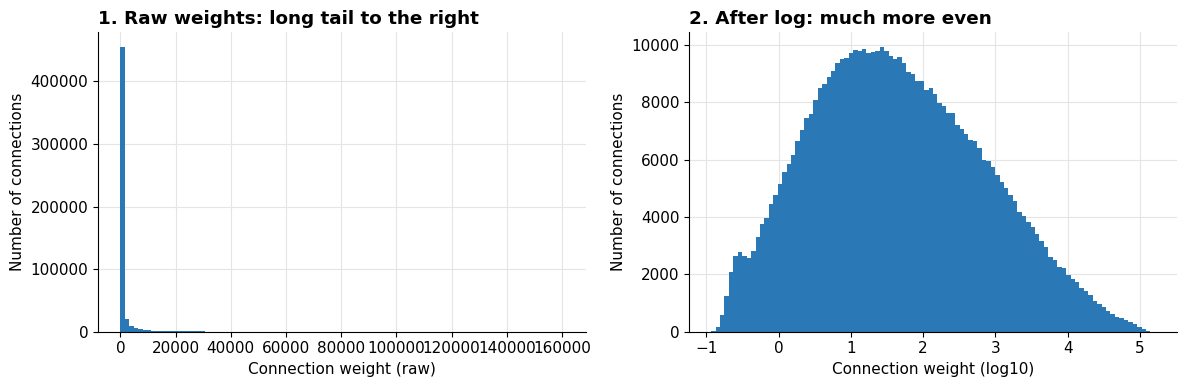

In [7]:
from scipy.stats import skew

iu = np.triu_indices(148, 1)
w = C148[:, iu[0], iu[1]]                             # 50 x (all region pairs)
nz = w[w > 0]
print(f"mean {nz.mean():.0f} | median {np.median(nz):.0f} | mean/median = {nz.mean()/np.median(nz):.1f}")
print(f"skewness raw: {skew(nz):.1f} | after log: {skew(np.log10(nz)):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(nz, bins=100, color="#2a78b5")
axes[0].set_xlabel("Connection weight (raw)"); axes[0].set_ylabel("Number of connections")
axes[0].set_title("1. Raw weights: long tail to the right", loc="left", fontweight="bold")
axes[1].hist(np.log10(nz), bins=100, color="#2a78b5")
axes[1].set_xlabel("Connection weight (log10)"); axes[1].set_ylabel("Number of connections")
axes[1].set_title("2. After log: much more even", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## How much do the 50 people agree?

density per person: median 0.95 (min 0.76, max 0.97)
connections present in >= 10% of people: 99.8%
connections present in >= 50% of people: 96.9%
connections present in >= 90% of people: 87.1%
connections present in >= 100% of people: 63.9%


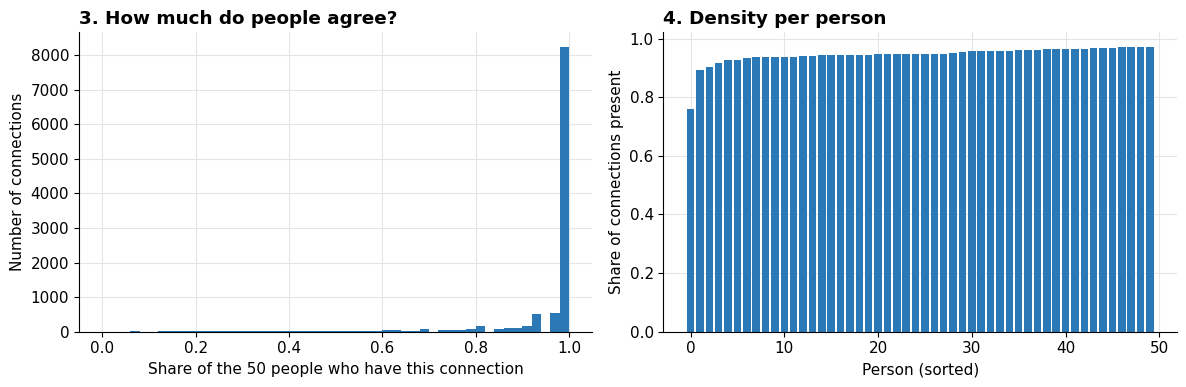

In [8]:
present = (w > 0).mean(axis=0)                        # share of people with each connection
density = (w > 0).mean(axis=1)                        # share of connections per person
print(f"density per person: median {np.median(density):.2f} (min {density.min():.2f}, max {density.max():.2f})")
for t in [0.1, 0.5, 0.9, 1.0]:
    print(f"connections present in >= {t:.0%} of people: {(present >= t).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(present, bins=50, color="#2a78b5")
axes[0].set_xlabel("Share of the 50 people who have this connection"); axes[0].set_ylabel("Number of connections")
axes[0].set_title("3. How much do people agree?", loc="left", fontweight="bold")
axes[1].bar(range(50), np.sort(density), color="#2a78b5")
axes[1].set_xlabel("Person (sorted)"); axes[1].set_ylabel("Share of connections present")
axes[1].set_title("4. Density per person", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## Is anyone very different from the group?

In [9]:
logw = np.log1p(w)
sim = pd.Series([np.corrcoef(logw[s], np.delete(logw, s, axis=0).mean(axis=0))[0, 1] for s in range(50)],
                index=subjects).sort_values()
print(sim.describe().round(3))
sim.head(5).round(3)

count    50.000
mean      0.952
std       0.018
min       0.866
25%       0.951
50%       0.957
75%       0.961
max       0.971
dtype: float64


sub-HC026    0.866
sub-HC023    0.883
sub-HC009    0.918
sub-HC011    0.931
sub-HC029    0.941
dtype: float64

## Compare three ways to combine

In [10]:
def to_matrix(v):
    A = np.zeros((148, 148)); A[iu] = v
    return A + A.T

versions = {
    "raw mean":         to_matrix(w.mean(axis=0)),
    "log mean":         to_matrix(np.log1p(w).mean(axis=0)),
    "consensus >= 50%": to_matrix(np.where(present >= 0.5, w.mean(axis=0), 0)),
}
summary = pd.DataFrame([dict(
    version=n,
    density=(A[iu] > 0).mean().round(3),
    mean_over_median=(A[iu][A[iu] > 0].mean() / np.median(A[iu][A[iu] > 0])).round(2),
) for n, A in versions.items()]).set_index("version")
print(summary)

strength = pd.DataFrame({n: A.sum(axis=0) for n, A in versions.items()})
print("\nrank correlation of region strength between versions:")
strength.corr(method="spearman").round(3)

                  density  mean_over_median
version                                    
raw mean            1.000             28.12
log mean            1.000              1.11
consensus >= 50%    0.969             25.96

rank correlation of region strength between versions:


,raw mean,log mean,consensus >= 50%
raw mean,1.000,0.865,1.000
log mean,0.865,1.000,0.865
consensus >= 50%,1.000,0.865,1.000


## Which regions have electrodes?

In [11]:
cc = load_ccep()
cov = pd.Series(0, index=pd.MultiIndex.from_frame(nodes[["hemisphere", "destrieux_nr"]]))
for p in cc:
    el = electrodes_tsv(p["id"], p["ses"])
    el = el[el["group"].isin(["grid", "strip"])]                       # surface electrodes only
    nr = pd.to_numeric(el["Destrieux_label"], errors="coerce")
    ok = el["hemisphere"].isin(["L", "R"]) & (nr > 0)
    for key in set(zip(el.loc[ok, "hemisphere"], nr[ok].astype(int))):
        if key in cov.index:
            cov[key] += 1
nodes["patients_with_electrodes"] = cov.values

print("regions covered by >= 1 patient:", (nodes["patients_with_electrodes"] > 0).sum(), "of 148")
print("never covered:", (nodes["patients_with_electrodes"] == 0).sum())
nodes[nodes["patients_with_electrodes"] == 0][["hemisphere", "label"]]

regions covered by >= 1 patient: 117 of 148
never covered: 31


,hemisphere,label
38,L,ctx_lh_Lat_Fis-ant-Horizont
39,L,ctx_lh_Lat_Fis-ant-Vertical
40,L,ctx_lh_Lat_Fis-post
45,L,ctx_lh_S_cingul-Marginalis
46,L,ctx_lh_S_circular_insula_ant
47,L,ctx_lh_S_circular_insula_inf
48,L,ctx_lh_S_circular_insula_sup
50,L,ctx_lh_S_collat_transv_post
59,L,ctx_lh_S_oc-temp_lat
64,L,ctx_lh_S_parieto_occipital
